# Customer Segmentation Using KMeans and DBSCAN

## Part A: Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN

In [2]:
df = pd.read_csv("Customer Segmentation Dataset.csv")
df

,Unnamed: 0,Income (k$),Spending Score (1-100),Age
0,0,20,15,22
1,1,22,18,25
2,2,18,12,21
3,3,25,20,28
4,4,23,14,24
5,5,19,22,26
6,6,27,17,23
7,7,21,10,29
8,8,80,85,24
9,9,85,90,27


In [3]:
df.drop(columns=["Unnamed: 0"], inplace=True)
df.head()

,Income (k$),Spending Score (1-100),Age
0,20,15,22
1,22,18,25
2,18,12,21
3,25,20,28
4,23,14,24


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Income (k$)             40 non-null     int64
 1   Spending Score (1-100)  40 non-null     int64
 2   Age                     40 non-null     int64
dtypes: int64(3)
memory usage: 1.1 KB


In [5]:
df.describe()

,Income (k$),Spending Score (1-100),Age
count,40.000000,40.000000,40.000000
mean,46.850000,45.225000,35.200000
std,31.751883,35.076099,12.531396
min,15.000000,10.000000,21.000000
25%,20.750000,15.000000,24.750000
50%,25.000000,22.000000,29.000000
75%,82.000000,85.250000,46.500000
max,95.000000,95.000000,58.000000


In [6]:
df.isnull().sum()

Income (k$)               0
Spending Score (1-100)    0
Age                       0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
X_scaled

array([[-0.8563918 , -0.87267537, -1.06677334],
       [-0.79260098, -0.78605747, -0.82432485],
       [-0.92018263, -0.95929327, -1.1475895 ],
       [-0.69691474, -0.7283122 , -0.58187637],
       [-0.76070557, -0.90154801, -0.90514101],
       [-0.88828721, -0.67056693, -0.74350869],
       [-0.63312392, -0.8149301 , -0.98595718],
       [-0.82449639, -1.01703854, -0.5010602 ],
       [ 1.0573329 ,  1.14840903, -0.90514101],
       [ 1.21680995,  1.2927722 , -0.66269253],
       [ 0.99354207,  1.06179113, -1.06677334],
       [ 1.37628701,  1.23502693, -0.42024404],
       [ 1.12112372,  1.43713537, -0.74350869],
       [ 1.31249619,  1.00404586, -0.58187637],
       [ 0.92975125,  1.35051747, -0.98595718],
       [ 1.44007784,  1.17728166, -0.33942788],
       [-0.92018263,  1.14840903, -0.90514101],
       [-0.79260098,  1.2927722 , -0.66269253],
       [-0.69691474,  1.06179113, -1.1475895 ],
       [-0.8563918 ,  1.43713537, -0.5010602 ],
       [-0.60122851,  1.23502693, -0.824

## Part B: KMeans

### Task 1: KMeans

In [9]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)
df.head()

,Income (k$),Spending Score (1-100),Age,KMeans_Cluster
0,20,15,22,2
1,22,18,25,2
2,18,12,21,2
3,25,20,28,2
4,23,14,24,2


In [10]:
df["KMeans_Cluster"].value_counts().sort_index()

KMeans_Cluster
0    16
1     8
2     8
3     8
Name: count, dtype: int64

In [11]:
centers_scaled = pd.DataFrame(kmeans.cluster_centers_, columns=df.columns[:3])
centers_scaled

,Income (k$),Spending Score (1-100),Age
0,0.190176,1.213372,-0.743509
1,-0.824496,-0.768012,1.165773
2,-0.796588,-0.843803,-0.844529
3,1.240732,-0.814930,1.165773


In [12]:
centers = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=df.columns[:3]
)
centers

,Income (k$),Spending Score (1-100),Age
0,52.8125,87.250,26.000
1,21.0000,18.625,49.625
2,21.8750,16.000,24.750
3,85.7500,17.000,49.625


### Task 2: Elbow Method

In [13]:
inertia = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

pd.DataFrame({"K": k_values, "Inertia": inertia})

,K,Inertia
0,1,120.000000
1,2,65.033468
2,3,37.203422
3,4,21.012073
4,5,5.291970
5,6,4.141707
6,7,3.149850
7,8,2.585977
8,9,2.244114
9,10,1.919669


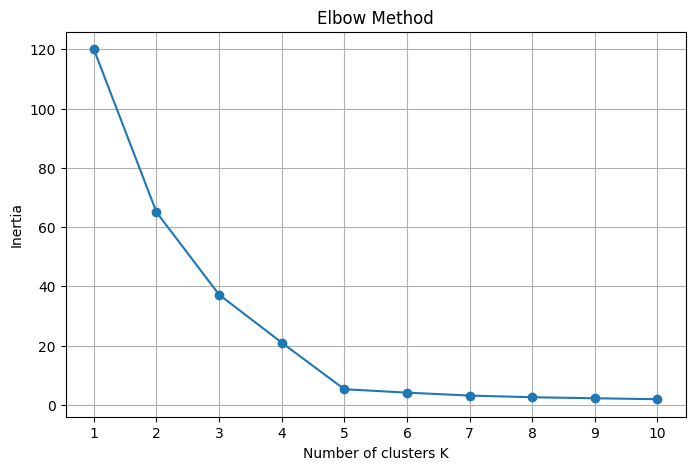

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of clusters K")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [15]:
drops = pd.Series(inertia).diff().abs().round(2)
pd.DataFrame({"K": k_values, "Inertia": inertia, "Drop": drops})

,K,Inertia,Drop
0,1,120.000000,NaN
1,2,65.033468,54.97
2,3,37.203422,27.83
3,4,21.012073,16.19
4,5,5.291970,15.72
5,6,4.141707,1.15
6,7,3.149850,0.99
7,8,2.585977,0.56
8,9,2.244114,0.34
9,10,1.919669,0.32


In [16]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)
df["KMeans_Cluster"].value_counts().sort_index()

KMeans_Cluster
0    8
1    8
2    8
3    8
4    8
Name: count, dtype: int64

### Task 3: Visualization

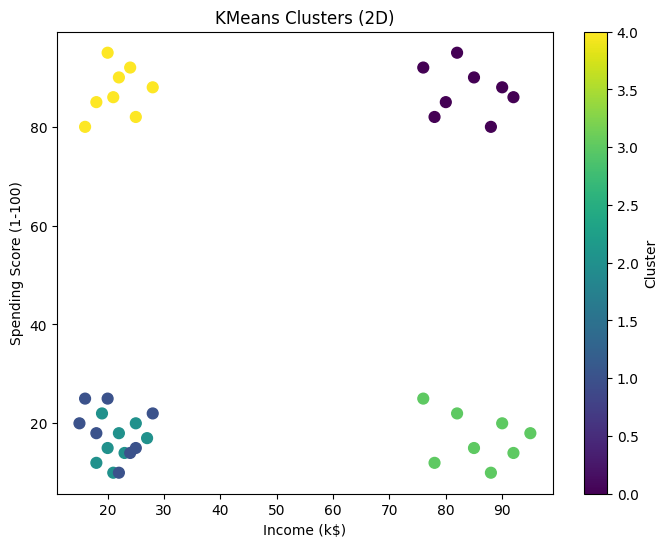

In [17]:
plt.figure(figsize=(8, 6))
plt.scatter(
    df["Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["KMeans_Cluster"],
    cmap="viridis",
    s=60
)
plt.xlabel("Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("KMeans Clusters (2D)")
plt.colorbar(label="Cluster")
plt.show()

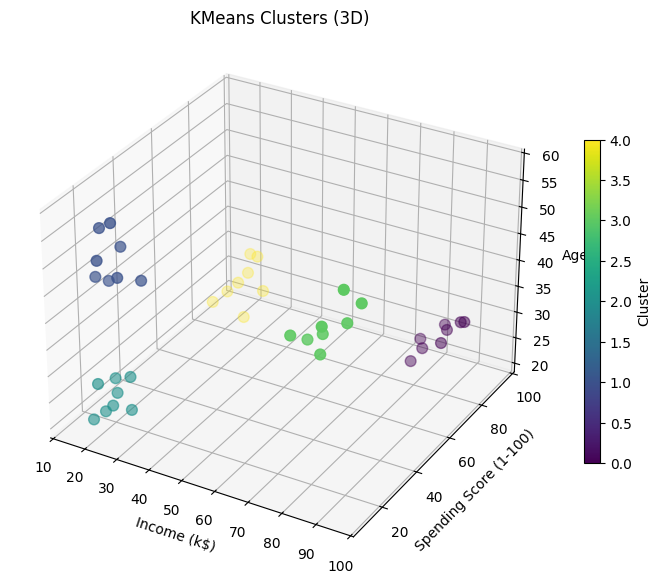

In [18]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
sc = ax.scatter(
    df["Income (k$)"],
    df["Spending Score (1-100)"],
    df["Age"],
    c=df["KMeans_Cluster"],
    cmap="viridis",
    s=60
)
ax.set_xlabel("Income (k$)")
ax.set_ylabel("Spending Score (1-100)")
ax.set_zlabel("Age")
ax.set_title("KMeans Clusters (3D)")
fig.colorbar(sc, label="Cluster", shrink=0.6)
plt.show()

## Part C: DBSCAN

### Task 1: Experiments

In [19]:
experiments = [
    (0.3, 3), (0.5, 3), (0.7, 3), (1.0, 3),
    (0.5, 5), (0.7, 5), (1.0, 5),
    (0.7, 8), (1.0, 8)
]

results = []
labels_dict = {}

for eps, min_samples in experiments:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    labels_dict[(eps, min_samples)] = labels
    results.append({
        "eps": eps,
        "min_samples": min_samples,
        "n_clusters": len(set(labels)) - (1 if -1 in labels else 0),
        "n_noise_points": int((labels == -1).sum())
    })

summary = pd.DataFrame(results)
summary

,eps,min_samples,n_clusters,n_noise_points
0,0.3,3,4,18
1,0.5,3,5,0
2,0.7,3,5,0
3,1.0,3,5,0
4,0.5,5,5,2
5,0.7,5,5,0
6,1.0,5,5,0
7,0.7,8,3,16
8,1.0,8,5,0


### Task 3: Visualization

In [20]:
selected = [(0.3, 3), (0.5, 3), (0.5, 5), (0.7, 8)]

def plot_dbscan_2d(labels, title):
    plt.figure(figsize=(7, 5))
    noise = labels == -1
    plt.scatter(
        df.loc[~noise, "Income (k$)"],
        df.loc[~noise, "Spending Score (1-100)"],
        c=labels[~noise], cmap="viridis", s=60
    )
    plt.scatter(
        df.loc[noise, "Income (k$)"],
        df.loc[noise, "Spending Score (1-100)"],
        c="red", marker="x", s=80, label="Noise"
    )
    plt.xlabel("Income (k$)")
    plt.ylabel("Spending Score (1-100)")
    plt.title(title)
    if noise.any():
        plt.legend()
    plt.show()

def plot_dbscan_3d(labels, title):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")
    noise = labels == -1
    ax.scatter(
        df.loc[~noise, "Income (k$)"],
        df.loc[~noise, "Spending Score (1-100)"],
        df.loc[~noise, "Age"],
        c=labels[~noise], cmap="viridis", s=60
    )
    ax.scatter(
        df.loc[noise, "Income (k$)"],
        df.loc[noise, "Spending Score (1-100)"],
        df.loc[noise, "Age"],
        c="red", marker="x", s=80, label="Noise"
    )
    ax.set_xlabel("Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.set_zlabel("Age")
    ax.set_title(title)
    if noise.any():
        ax.legend()
    plt.show()

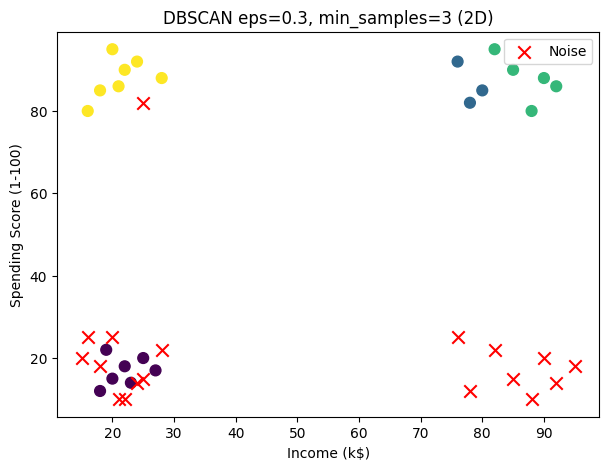

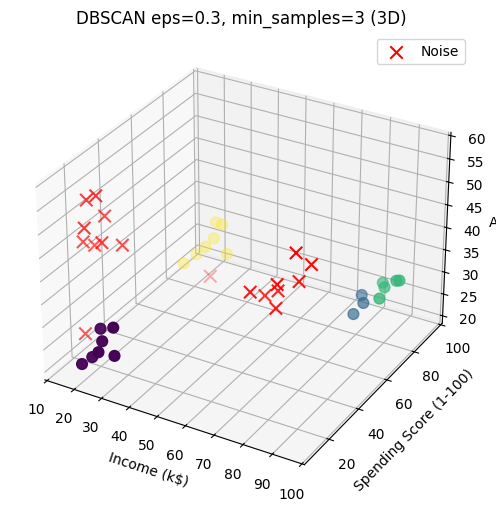

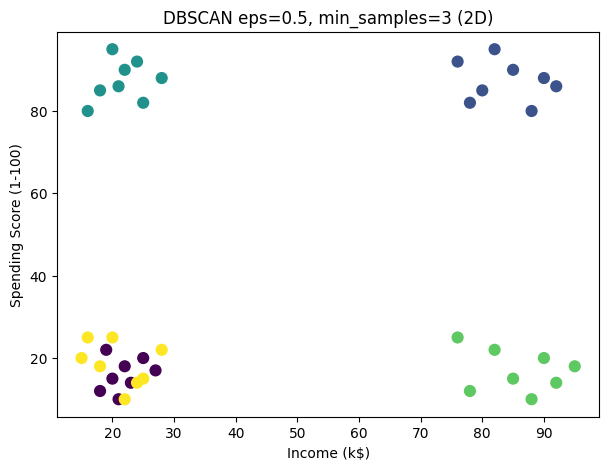

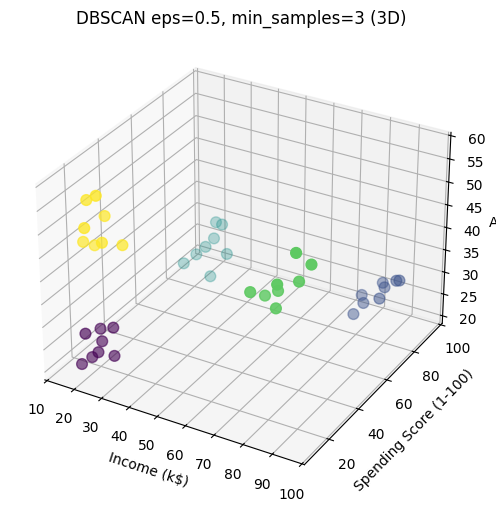

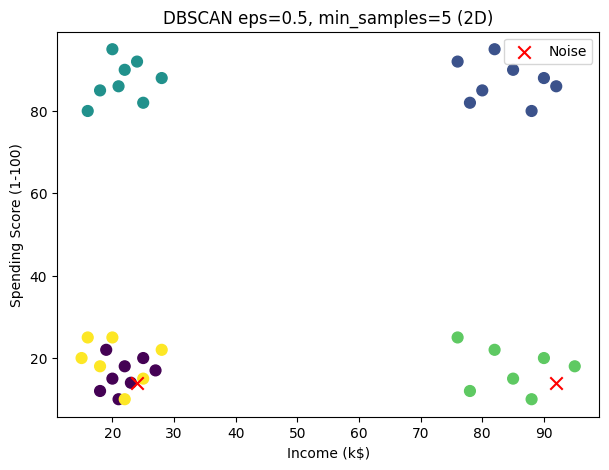

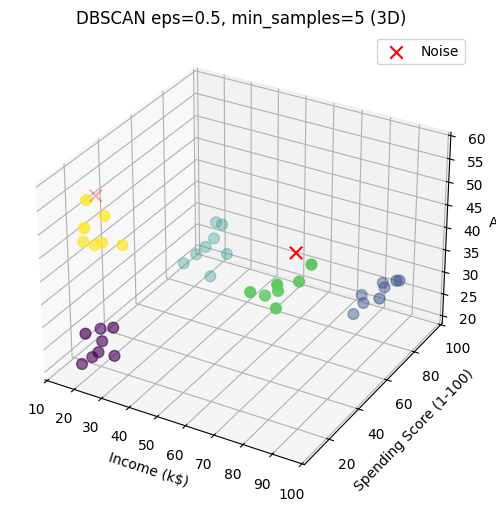

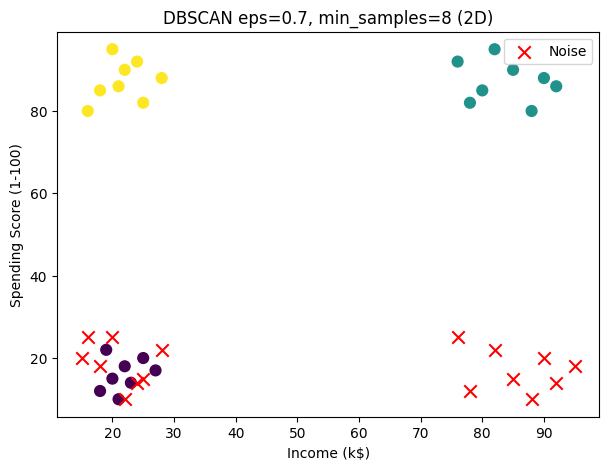

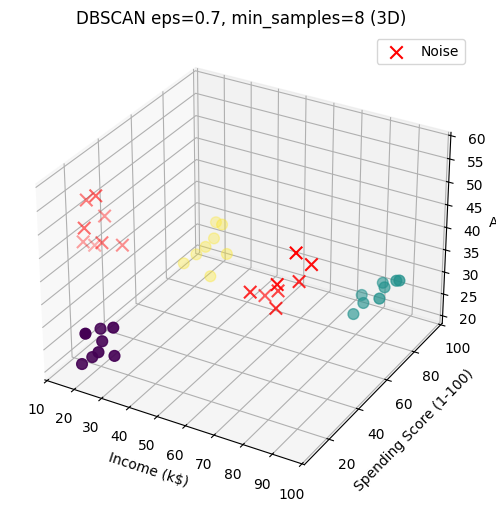

In [21]:
for eps, min_samples in selected:
    labels = labels_dict[(eps, min_samples)]
    title = f"DBSCAN eps={eps}, min_samples={min_samples}"
    plot_dbscan_2d(labels, title + " (2D)")
    plot_dbscan_3d(labels, title + " (3D)")

## Part D: KMeans vs. DBSCAN

In [22]:
comparison = pd.DataFrame({
    "Comparison criterion": [
        "Main parameters",
        "Requires the number of clusters beforehand?",
        "Cluster assignment approach",
        "Can identify noise points?",
        "Sensitivity to feature scaling",
        "Suitable for non-spherical clusters?"
    ],
    "KMeans": [
        "n_clusters",
        "Yes",
        "Distance to nearest centroid",
        "No",
        "High",
        "No"
    ],
    "DBSCAN": [
        "eps, min_samples",
        "No",
        "Density-based",
        "Yes",
        "High",
        "Yes"
    ]
})
comparison

,Comparison criterion,KMeans,DBSCAN
0,Main parameters,n_clusters,"eps, min_samples"
1,Requires the number of clusters beforehand?,Yes,No
2,Cluster assignment approach,Distance to nearest centroid,Density-based
3,Can identify noise points?,No,Yes
4,Sensitivity to feature scaling,High,High
5,Suitable for non-spherical clusters?,No,Yes
